# The GPU path: detection, single and batched evaluation

Monod evaluates a model's steady-state distribution in one of three places: on a CUDA GPU through PyTorch, on the CPU through the Rust accelerator, or in pure Python. The choice is made per call, in that order of preference, and needs no configuration. This notebook shows how the choice is made, what the GPU costs and buys for a single evaluation and for a thousand at once, and why the gain is smaller inside a real fit, where every gene has its own grid.

**What runs on the GPU.** The six two-species transcription models (`Constitutive`, `Bursty`, `CIR`, `Extrinsic`, `Delay`, `DelayedSplicing`) with no sequencing noise or with Poisson or Bernoulli noise. The ambiguous-assignment models, the protein model and custom networks stay on the Rust path. The GPU must support float64: CUDA devices do, Apple MPS does not, so on a Mac the Rust path is used.

**Opting out.** Hide the device before importing monod, for example `CUDA_VISIBLE_DEVICES=""` in the environment; monod then never sees it.

**Requirements for this notebook.** PyTorch with CUDA and the Rust accelerator. It was executed on an RTX 3070, a consumer card whose float64 throughput is a sixty-fourth of its float32 rate, next to 24 CPU cores. Datacentre cards change the ratios in section 2 considerably; the structure of the comparison does not change.

## Contents

1. Which backend runs: the probe and the decision  
2. One evaluation at a time: GPU, Rust and Python compared  
3. Many genes at once: `eval_model_pss_batch`  
4. What limits the GPU path


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import time, warnings, logging
import unittest.mock as mock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import monod.cme_toolbox as ct
from monod.cme_toolbox import CMEModel
logging.getLogger('monod').setLevel(logging.WARNING)
warnings.filterwarnings('ignore', category=FutureWarning)
import os; os.makedirs('figures', exist_ok=True)

try:
    import torch
    print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available(),
          '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no device')
except ImportError:
    print('torch not installed')
print('monod sees a float64-capable GPU:', ct._HAS_GPU, '| device:', ct._GPU_DEVICE, '| Rust accelerator:', ct._HAS_RUST)


torch 2.5.1+cu121 | CUDA available: True | NVIDIA GeForce RTX 3070
monod sees a float64-capable GPU: True | device: cuda | Rust accelerator: True


---
## 1 · Which backend runs

At import time monod probes the GPU with a small float64 operation. If it succeeds, every evaluation of a supported model goes to the GPU; the decision for a given model is visible through `CMEModel._backend`, which returns the kind of backend and the kernel family.


In [3]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for label, model in [
        ('Bursty, no noise',              CMEModel('Bursty', 'None')),
        ('Bursty, Poisson noise',         CMEModel('Bursty', 'Poisson')),
        ('Bursty, Bernoulli noise',       CMEModel('Bursty', 'Bernoulli')),
        ('Delay, no noise',               CMEModel('Delay', 'None')),
        ('Bursty + ambiguous assignment', CMEModel('Bursty', 'None', amb_model='Equal')),
        ('ProteinBursty',                 CMEModel('ProteinBursty', 'None')),
        ('Custom network',                CMEModel('Custom', 'None', network='0 -> B x U -> S -> 0', normalize_production_rate=True)),
    ]:
        samp = [-1.0, -0.5] if model.seq_model != 'None' else None
        be = model._backend(samp)
        rows.append((label, be.kind, be.family))
pd.DataFrame(rows, columns=['model', 'backend', 'kernel family'])


,model,backend,kernel family
0,"Bursty, no noise",gpu,2d
1,"Bursty, Poisson noise",gpu,2d
2,"Bursty, Bernoulli noise",gpu,2d
3,"Delay, no noise",gpu,2d
4,Bursty + ambiguous assignment,rust,amb
5,ProteinBursty,rust,protein
6,Custom network,rust,custom


---
## 2 · One evaluation at a time

A single steady-state evaluation on a 120 by 80 grid, timed on each backend. The Rust and Python timings are obtained by telling monod the GPU, and then the accelerator, is unavailable. The first GPU call includes CUDA start-up and is excluded by a warm-up call.


In [4]:
LIMITS = [120, 80]
p_bursty = np.log10([8.0, 1.0, 0.4])
samp_pois = np.log10([0.2, 0.5])

def timeit(fn, n=20):
    fn()                                            # warm-up
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1e3 * np.median(t)

def on_backend(kind, fn):
    if kind == 'gpu':
        return fn()
    if kind == 'rust':
        with mock.patch.object(ct, '_HAS_GPU', False):
            return fn()
    with mock.patch.object(ct, '_HAS_GPU', False), mock.patch.object(ct, '_HAS_RUST', False):
        return fn()

rows, ref = [], {}
for label, model, samp in [('Bursty / None', CMEModel('Bursty', 'None'), None),
                           ('Bursty / Poisson', CMEModel('Bursty', 'Poisson'), samp_pois)]:
    out = {}
    for kind in ('gpu', 'rust', 'python'):
        ms = on_backend(kind, lambda: timeit(lambda: model.eval_model_pss(p_bursty, LIMITS, samp), n=20 if kind != 'python' else 5))
        out[kind] = (ms, on_backend(kind, lambda: model.eval_model_pss(p_bursty, LIMITS, samp)))
    rows.append((label, out['gpu'][0], out['rust'][0], out['python'][0],
                 np.abs(out['gpu'][1] - out['rust'][1]).max(), np.abs(out['rust'][1] - out['python'][1]).max()))
single = pd.DataFrame(rows, columns=['model', 'GPU ms', 'Rust ms', 'Python ms', 'max |GPU - Rust|', 'max |Rust - Python|'])
single.round(4)


,model,GPU ms,Rust ms,Python ms,max |GPU - Rust|,max |Rust - Python|
0,Bursty / None,2.4695,2.5186,6.4639,0.0,0.0
1,Bursty / Poisson,2.2515,2.5395,6.3751,0.0,0.0


For a single gene the three agree to numerical precision and the GPU is only modestly ahead of 24 Rust threads: launching a handful of kernels and copying the result back costs about as much as the arithmetic. Exploratory work on one gene at a time gains little from the device.

---
## 3 · Many genes at once

`eval_model_pss_batch` takes a list of parameter vectors and grid sizes, groups the genes by grid size, and evaluates each group in one batched call: one tensor of all grids times all quadrature nodes, chunked to stay under 512 MB, and one batched inverse FFT. On the Rust path the same call runs the genes in parallel on the thread pool. The per-gene cost is what matters here.


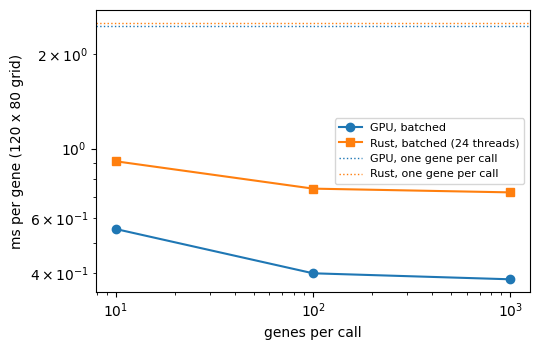

,genes,GPU ms,GPU ms per gene,Rust ms,Rust ms per gene,max |GPU - Rust|
0,10,5.5413,0.5541,9.1124,0.9112,0.0
1,100,40.0376,0.4004,74.5490,0.7455,0.0
2,1000,383.1060,0.3831,725.2325,0.7252,0.0


In [5]:
rng = np.random.default_rng(0)
model = CMEModel('Bursty', 'None')

def random_params(n):
    return [np.array([rng.uniform(0.0, 2.0), rng.uniform(-1.0, 1.0), rng.uniform(-1.0, 1.0)]) for _ in range(n)]

rows = []
for n in (10, 100, 1000):
    params = random_params(n); limits = [LIMITS] * n
    gpu_ms = on_backend('gpu', lambda: timeit(lambda: model.eval_model_pss_batch(params, limits), n=5))
    rust_ms = on_backend('rust', lambda: timeit(lambda: model.eval_model_pss_batch(params, limits), n=5))
    a = on_backend('gpu', lambda: model.eval_model_pss_batch(params, limits))
    b = on_backend('rust', lambda: model.eval_model_pss_batch(params, limits))
    rows.append((n, gpu_ms, gpu_ms / n, rust_ms, rust_ms / n, max(np.abs(x - y).max() for x, y in zip(a, b))))
batch = pd.DataFrame(rows, columns=['genes', 'GPU ms', 'GPU ms per gene', 'Rust ms', 'Rust ms per gene', 'max |GPU - Rust|'])

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(batch['genes'], batch['GPU ms per gene'], 'o-', label='GPU, batched')
ax.plot(batch['genes'], batch['Rust ms per gene'], 's-', label='Rust, batched (24 threads)')
ax.axhline(single.loc[0, 'GPU ms'], color='C0', ls=':', lw=1, label='GPU, one gene per call')
ax.axhline(single.loc[0, 'Rust ms'], color='C1', ls=':', lw=1, label='Rust, one gene per call')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('genes per call'); ax.set_ylabel('ms per gene (120 x 80 grid)')
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig('figures/gpu_batch_scaling.png', dpi=130); plt.show()
batch.round(4)


Batching is what the GPU is for. Per gene, the batched GPU evaluation is several times cheaper than a single call, and it pulls ahead of the Rust thread pool once a few hundred genes share a call. The copy back to host memory is a fixed part of the cost; monod moves the whole batch in one transfer rather than gene by gene.

---
## 4 · What limits the GPU path

- **Float64 throughput.** The steady state is computed in double precision because the generating function is exponentiated and inverted by FFT; single precision loses the tail of the distribution. Consumer NVIDIA cards run float64 at a small fraction of their float32 rate, so the arithmetic itself is not much faster than a good CPU. Datacentre cards (A100, H100) have full-rate float64 and shift every comparison above toward the GPU.
- **Launch and transfer overhead.** A single evaluation is dominated by fixed costs. Batching amortises them, but only across genes that share a grid size. In a real fit each gene gets its own grid from its own count range, so a batch of genes splits into nearly one launch per gene, and the GPU pays its fixed cost every time while the Rust thread pool simply runs many small jobs; padding genes to a few shared grid sizes would restore the batching. The batch is chunked so that the intermediate tensor stays under 512 MB (`_GPU_BATCH_BYTES`), which is why 1000 genes on a 120 by 80 grid fit on an 8 GB card.
- **Coverage.** The ambiguous-assignment models, the protein model and custom networks have no GPU kernel; they use the Rust path regardless of the device.
- **Apple silicon.** MPS has no float64 support, so monod's probe fails and the Rust path is used. This is detected at import, not at call time.

In short: leave detection on and expect the GPU to matter when many genes share a grid. The fit itself runs in the Rust L-BFGS-B kernel, gene by gene across the thread pool; the GPU enters through `eval_model_pss` and `eval_model_pss_batch`, the evaluations shown in sections 2 and 3.
